# Modified K-Means Clustering

## 1. Objective

The objective of this experiment is to implement a modified version of the K-Means clustering algorithm and compare its performance with the standard K-Means algorithm.

The experiment focuses on:

- Understanding the limitations of standard K-Means.
- Implementing a modified centroid initialization strategy.
- Applying clustering to the Iris dataset.
- Visualizing the generated clusters.
- Evaluating clustering performance using different metrics.
- Comparing Standard K-Means and Modified K-Means.
- Investigating the effect of centroid initialization on clustering results.


##  Theory

### Standard K-Means

K-Means is an unsupervised learning algorithm that partitions a dataset into K clusters.

Each cluster is represented by a centroid.

The algorithm iteratively assigns data points to their nearest centroid and updates the centroids by calculating the mean of the assigned data points.

### Limitations of Standard K-Means

- Random centroid initialization may produce different results.
- Poor initial centroids may lead to local optima.
- The algorithm is sensitive to outliers.
- The number of clusters K must be specified in advance.
- It works best when clusters are relatively compact and spherical.

### Modified K-Means

In this experiment, a modified version of K-Means is implemented using a data-driven centroid initialization strategy.

Instead of relying on randomly selected initial centroids, the initial centroids are selected using the following approach:

1. Select the first centroid based on the dataset mean.
2. Select subsequent centroids based on their distance from the previously selected centroids.
3. Prefer data points that are relatively far from existing centroids.
4. Apply the standard assignment and centroid update steps.

The objective is to improve the initial centroid placement and investigate its effect on clustering results.

### Algorithm Steps

1. Standardize the input features.
2. Select the first centroid using the dataset mean.
3. Calculate distances from the existing centroids.
4. Select the next centroid from a data point with a large minimum distance.
5. Repeat until K initial centroids are selected.
6. Assign each data point to its nearest centroid.
7. Update each centroid using the mean of its assigned data points.
8. Repeat until the centroids converge or the maximum number of iterations is reached.


## 3. Dataset Information

**Dataset:** Iris Species Dataset

**Source:** Kaggle

**Link:** https://www.kaggle.com/datasets/uciml/iris

The Iris dataset contains 150 samples belonging to three flower species.

Each sample contains four numerical features:

- SepalLengthCm
- SepalWidthCm
- PetalLengthCm
- PetalWidthCm

The Species column is not used during clustering.

The actual species labels are preserved for evaluation and comparison purposes.


## Import Required Libraries

The following libraries are used for data preprocessing, clustering, visualization, and evaluation.


In [1]:
!pip install -q kagglehub

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_style("whitegrid")

In [3]:
# Download dataset

path = kagglehub.dataset_download("uciml/iris")

print("Dataset Path:", path)
print("Files:", os.listdir(path))

Using Colab cache for faster access to the 'iris' dataset.
Dataset Path: /kaggle/input/iris
Files: ['Iris.csv', 'database.sqlite']


In [4]:
# Load dataset

df = pd.read_csv(os.path.join(path, "Iris.csv"))

display(df.head())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


##  Dataset Exploration

The dataset is examined to understand its structure, features, data types, and statistical properties before applying the clustering algorithms.


In [5]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate values
print("\nDuplicate Rows:", df.duplicated().sum())

# Species distribution
print("\nSpecies Distribution:")
print(df["Species"].value_counts())

Dataset Shape: (150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate Rows: 0

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


### Dataset Observation

The dataset contains four numerical features and one categorical target column.

The Species column contains the actual flower species and will not be used during clustering.


##  Data Preprocessing

### Feature Selection

The Id column is removed because it does not contain meaningful measurement information.

The Species column is excluded from clustering because K-Means is an unsupervised algorithm.

Only the four numerical features are selected for training.

### Feature Scaling

StandardScaler is applied to transform the numerical features to approximately zero mean and unit variance.

Feature scaling is necessary because K-Means uses distance calculations and features with larger numerical ranges may dominate the clustering process.


In [6]:
# Remove Id column
df = df.drop(columns=["Id"])

# Save actual species for evaluation
actual_species = df["Species"].copy()

# Select features
X = df.drop(columns=["Species"])

print("Selected Features:")
display(X.head())

print("Feature Shape:", X.shape)

Selected Features:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Feature Shape: (150, 4)


In [7]:
# Standardization

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Feature Shape:", X_scaled.shape)

Scaled Feature Shape: (150, 4)


In [8]:
# Create DataFrame of scaled features

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

display(X_scaled_df.head())

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


## Standard K-Means

Standard K-Means is implemented using the Scikit-learn library.

The number of clusters is set to 3 based on the three known Iris species.

The actual species labels are not used during training.


In [9]:
# Initialize Standard K-Means

k = 3

standard_kmeans = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

# Train model
standard_kmeans.fit(X_scaled)

# Cluster labels
standard_labels = standard_kmeans.labels_

# Centroids
standard_centroids = standard_kmeans.cluster_centers_

print("Standard K-Means Completed!")
print("Iterations:", standard_kmeans.n_iter_)
print("Inertia:", standard_kmeans.inertia_)

Standard K-Means Completed!
Iterations: 4
Inertia: 140.96581663074699


In [10]:
# Standard K-Means evaluation

standard_silhouette = silhouette_score(
    X_scaled,
    standard_labels
)

standard_ari = adjusted_rand_score(
    actual_species,
    standard_labels
)

print("Standard K-Means Results")
print("-" * 35)
print("Inertia:", round(standard_kmeans.inertia_, 4))
print("Silhouette Score:", round(standard_silhouette, 4))
print("Adjusted Rand Index:", round(standard_ari, 4))

Standard K-Means Results
-----------------------------------
Inertia: 140.9658
Silhouette Score: 0.459
Adjusted Rand Index: 0.6201


##  Modified K-Means Algorithm

### Modified Centroid Initialization

The initial centroids are selected using a farthest-point initialization strategy.

#### Step 1: Select the First Centroid

Calculate the mean of the dataset and select the actual data point closest to the mean as the first centroid.

#### Step 2: Calculate Minimum Distances

For every data point, calculate its distance to the nearest selected centroid.

#### Step 3: Select the Next Centroid

Select the data point having the largest minimum distance from the existing centroids.

#### Step 4: Repeat

Repeat the selection process until K initial centroids are selected.

#### Step 5: Perform K-Means Iterations

After initialization:

- Assign data points to the nearest centroid.
- Update centroids using the mean of assigned points.
- Repeat until convergence.


In [11]:
# Euclidean distance function

def euclidean_distance(point1, point2):

    distance = np.sqrt(
        np.sum((point1 - point2) ** 2)
    )

    return distance

In [12]:
# Modified centroid initialization

def initialize_centroids_farthest(X, k):

    n_samples = X.shape[0]

    # Step 1: Calculate dataset mean
    data_mean = np.mean(X, axis=0)

    # Select data point closest to mean
    first_index = np.argmin(
        np.linalg.norm(X - data_mean, axis=1)
    )

    centroids = [X[first_index]]

    selected_indices = [first_index]

    # Step 2: Select remaining centroids
    for _ in range(k - 1):

        # Calculate distance from every point
        # to each selected centroid
        distances = np.zeros(n_samples)

        for i in range(n_samples):

            point_distances = []

            for centroid in centroids:

                dist = euclidean_distance(
                    X[i],
                    centroid
                )

                point_distances.append(dist)

            # Minimum distance to selected centroids
            distances[i] = min(point_distances)

        # Avoid selecting the same data point
        distances[selected_indices] = -1

        # Select point with maximum minimum distance
        next_index = np.argmax(distances)

        centroids.append(X[next_index])

        selected_indices.append(next_index)

    return np.array(centroids)

### Modified K-Means Implementation

The modified K-Means algorithm is implemented manually.

The algorithm uses the farthest-point initialization method to select initial centroids.

After initialization, the standard assignment and centroid update steps are repeated until convergence or the maximum number of iterations is reached.

If a cluster becomes empty, its centroid is reinitialized using a data point farthest from the currently assigned centroids.


In [13]:
# Modified K-Means algorithm

def modified_kmeans(X, k, max_iter=300, tol=1e-4):

    # Step 1: Initialize centroids
    centroids = initialize_centroids_farthest(X, k)

    n_samples = X.shape[0]

    labels = np.zeros(n_samples, dtype=int)

    for iteration in range(max_iter):

        # Step 2: Assign data points to nearest centroid
        for i in range(n_samples):

            distances = []

            for centroid in centroids:

                dist = euclidean_distance(
                    X[i],
                    centroid
                )

                distances.append(dist)

            labels[i] = np.argmin(distances)

        # Step 3: Update centroids
        new_centroids = np.zeros_like(centroids)

        for cluster in range(k):

            cluster_points = X[labels == cluster]

            if len(cluster_points) > 0:

                new_centroids[cluster] = np.mean(
                    cluster_points,
                    axis=0
                )

            else:

                # Handle empty cluster
                distances_to_centroids = np.zeros(n_samples)

                for i in range(n_samples):

                    distances_to_centroids[i] = min(
                        euclidean_distance(X[i], centroid)
                        for centroid in centroids
                    )

                farthest_index = np.argmax(
                    distances_to_centroids
                )

                new_centroids[cluster] = X[farthest_index]

        # Step 4: Check convergence
        centroid_shift = np.linalg.norm(
            new_centroids - centroids
        )

        centroids = new_centroids

        if centroid_shift < tol:

            print("Converged at iteration:", iteration + 1)

            break

    # Final assignment
    for i in range(n_samples):

        distances = []

        for centroid in centroids:

            dist = euclidean_distance(
                X[i],
                centroid
            )

            distances.append(dist)

        labels[i] = np.argmin(distances)

    # Calculate Inertia / WCSS
    inertia = 0

    for i in range(n_samples):

        assigned_centroid = centroids[labels[i]]

        inertia += np.sum(
            (X[i] - assigned_centroid) ** 2
        )

    return labels, centroids, inertia, iteration + 1

In [14]:
# Train Modified K-Means

modified_labels, modified_centroids, modified_inertia, modified_iterations = modified_kmeans(
    X_scaled,
    k=3,
    max_iter=300,
    tol=1e-4
)

print("\nModified K-Means Training Completed!")
print("Number of Iterations:", modified_iterations)
print("Inertia:", modified_inertia)

Converged at iteration: 7

Modified K-Means Training Completed!
Number of Iterations: 7
Inertia: 141.15417813388657


In [15]:
# Display Modified K-Means cluster distribution

modified_cluster_counts = pd.Series(
    modified_labels
).value_counts().sort_index()

print("Modified K-Means Cluster Distribution:")
display(modified_cluster_counts)

Modified K-Means Cluster Distribution:


,count
0,56
1,50
2,44


In [16]:
# Add modified cluster labels to DataFrame

df["Modified_Cluster"] = modified_labels

display(df.head(10))

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Modified_Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5.0,3.6,1.4,0.2,Iris-setosa,1
5,5.4,3.9,1.7,0.4,Iris-setosa,1
6,4.6,3.4,1.4,0.3,Iris-setosa,1
7,5.0,3.4,1.5,0.2,Iris-setosa,1
8,4.4,2.9,1.4,0.2,Iris-setosa,1
9,4.9,3.1,1.5,0.1,Iris-setosa,1



##  Modified K-Means Centroids

The centroids represent the mean feature values of the data points assigned to each cluster.

Since the model was trained using standardized features, the centroids are initially represented in standardized space.

The centroids are also converted back to the original feature scale for easier interpretation.


In [17]:
# Centroids in scaled space

modified_centroids_df = pd.DataFrame(
    modified_centroids,
    columns=X.columns
)

modified_centroids_df.index.name = "Cluster"

display(modified_centroids_df)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,-0.011396,-0.872885,0.376884,0.311654
1,-1.014579,0.842307,-1.304878,-1.255129
2,1.167434,0.153778,1.003145,1.029633


In [18]:
# Convert centroids to original scale

modified_centroids_original = scaler.inverse_transform(
    modified_centroids
)

modified_centroids_original_df = pd.DataFrame(
    modified_centroids_original,
    columns=X.columns
)

modified_centroids_original_df.index.name = "Cluster"

display(modified_centroids_original_df)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.833929,2.676786,4.421429,1.435714
1,5.006000,3.418000,1.464000,0.244000
2,6.806818,3.120455,5.522727,1.981818



## Cluster Visualization

The generated clusters are visualized using PetalLengthCm and PetalWidthCm.

Although the Modified K-Means model uses all four standardized features, two features are displayed for visualization.

The modified cluster centroids are also displayed on the scatter plot.


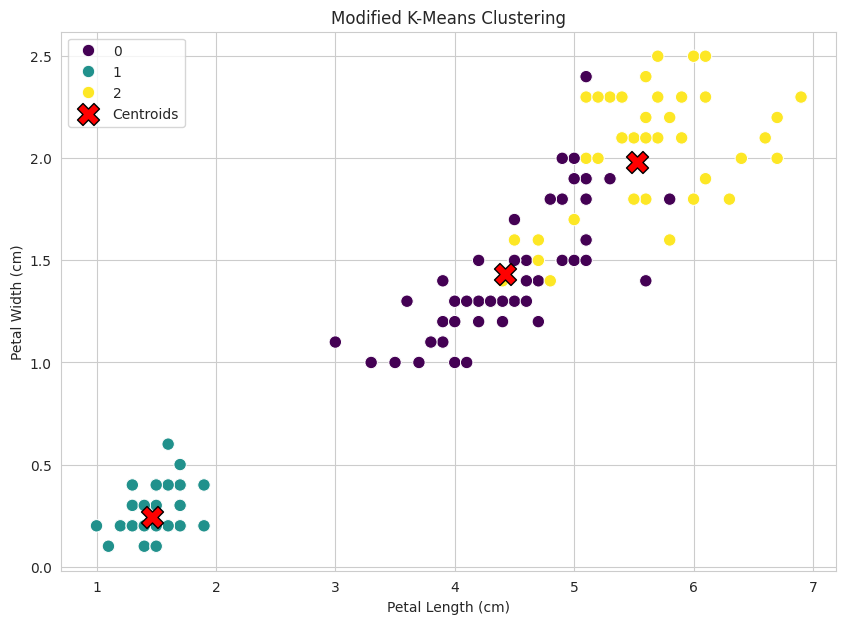

In [19]:
# Visualize Modified K-Means clusters

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X["PetalLengthCm"],
    y=X["PetalWidthCm"],
    hue=modified_labels,
    palette="viridis",
    s=80
)

# Plot modified centroids
plt.scatter(
    modified_centroids_original[:, 2],
    modified_centroids_original[:, 3],
    marker="X",
    s=250,
    color="red",
    edgecolor="black",
    label="Centroids"
)

plt.title("Modified K-Means Clustering")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.legend()
plt.show()


### Observation

The visualization shows the clusters generated by the Modified K-Means algorithm.

The red markers represent cluster centroids.

The distribution of clusters can be examined to determine whether the initialization strategy produces compact and well-separated groups.



## PCA Visualization

Principal Component Analysis (PCA) is used to project the four-dimensional standardized dataset into a two-dimensional space.

The clustering algorithm is trained using all four features.

PCA is used only for visualization purposes.


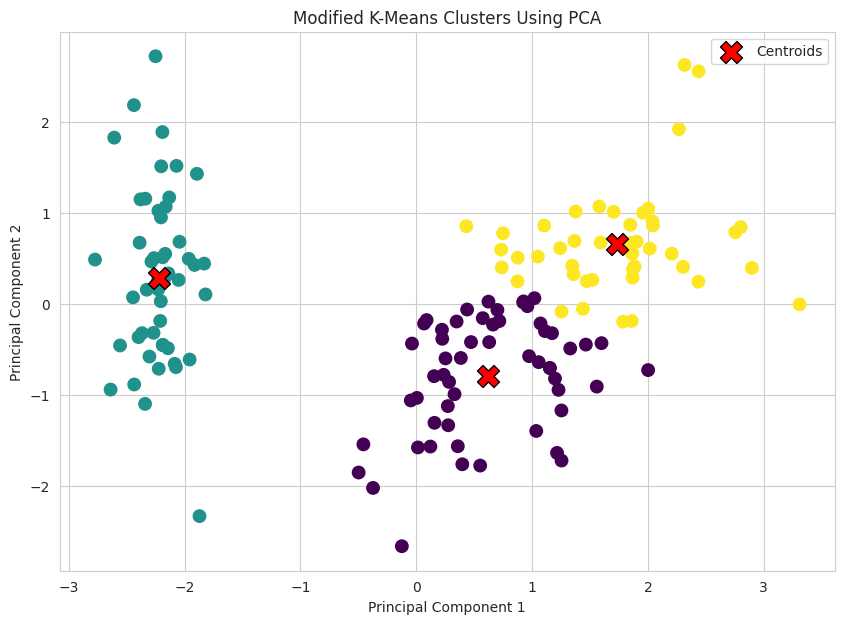

In [20]:
from sklearn.decomposition import PCA

# PCA dimensionality reduction
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Transform Modified K-Means centroids
modified_centroids_pca = pca.transform(
    modified_centroids
)

# Plot clusters
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=modified_labels,
    cmap="viridis",
    s=80
)

plt.scatter(
    modified_centroids_pca[:, 0],
    modified_centroids_pca[:, 1],
    marker="X",
    color="red",
    s=250,
    edgecolor="black",
    label="Centroids"
)

plt.title("Modified K-Means Clusters Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.show()

In [21]:
# Explained variance

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total Variance Explained:",
    pca.explained_variance_ratio_.sum()
)

Explained Variance Ratio:
[0.72770452 0.23030523]
Total Variance Explained: 0.9580097536148199



## Evaluation

### Silhouette Score

The Silhouette Score measures how well data points fit within their assigned clusters compared to other clusters.

A higher score generally indicates better cluster separation and cohesion.


In [22]:
# Modified K-Means Silhouette Score

modified_silhouette = silhouette_score(
    X_scaled,
    modified_labels
)

print(
    "Modified K-Means Silhouette Score:",
    round(modified_silhouette, 4)
)

Modified K-Means Silhouette Score: 0.4621



### Adjusted Rand Index (ARI)

The Adjusted Rand Index compares the generated cluster assignments with the actual Iris species labels.

The actual labels are not used during training.

ARI measures agreement between the clustering structure and the known class structure while adjusting for chance.


In [23]:
# Modified K-Means ARI

modified_ari = adjusted_rand_score(
    actual_species,
    modified_labels
)

print(
    "Modified K-Means ARI:",
    round(modified_ari, 4)
)

Modified K-Means ARI: 0.5923


In [24]:
print("Modified K-Means Inertia:", modified_inertia)

Modified K-Means Inertia: 141.15417813388657



## Actual Species Comparison

The cluster labels generated by Modified K-Means are compared with the actual Iris species.

The actual species labels were not used for training.

This comparison helps evaluate how well the generated clusters represent the original flower categories.


In [25]:
# Create comparison table

modified_comparison = pd.DataFrame({
    "Actual Species": actual_species,
    "Modified Cluster": modified_labels
})

display(modified_comparison.head(10))

,Actual Species,Modified Cluster
0,Iris-setosa,1
1,Iris-setosa,1
2,Iris-setosa,1
3,Iris-setosa,1
4,Iris-setosa,1
5,Iris-setosa,1
6,Iris-setosa,1
7,Iris-setosa,1
8,Iris-setosa,1
9,Iris-setosa,1


In [26]:
# Cross-tabulation

modified_crosstab = pd.crosstab(
    actual_species,
    modified_labels
)

display(modified_crosstab)

col_0,0,1,2
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,17,0,33


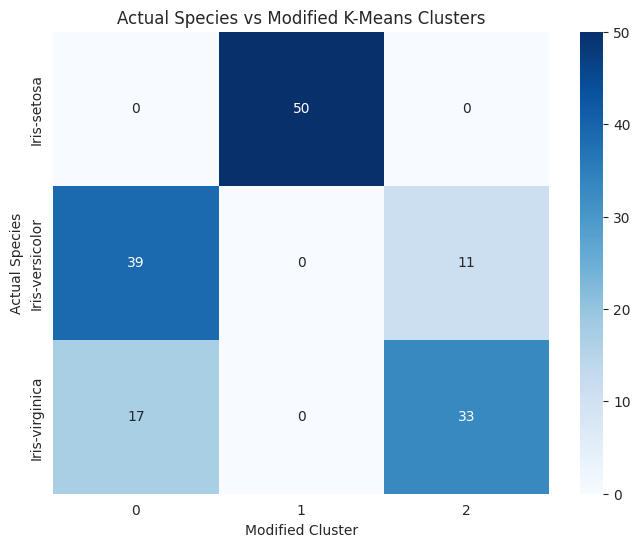

In [27]:
# Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    modified_crosstab,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Species vs Modified K-Means Clusters")
plt.xlabel("Modified Cluster")
plt.ylabel("Actual Species")

plt.show()


##  Standard K-Means vs Modified K-Means

Both algorithms are evaluated using the same standardized Iris dataset and the same number of clusters.

The following metrics are compared:

- Inertia (WCSS)
- Silhouette Score
- Adjusted Rand Index (ARI)
- Number of iterations

The comparison helps investigate the effect of centroid initialization on clustering performance.


In [28]:
# Create performance comparison table

comparison_results = pd.DataFrame({
    "Algorithm": [
        "Standard K-Means",
        "Modified K-Means"
    ],

    "Inertia (WCSS)": [
        standard_kmeans.inertia_,
        modified_inertia
    ],

    "Silhouette Score": [
        standard_silhouette,
        modified_silhouette
    ],

    "Adjusted Rand Index": [
        standard_ari,
        modified_ari
    ],

    "Iterations": [
        standard_kmeans.n_iter_,
        modified_iterations
    ]
})

display(
    comparison_results.round(4)
)

,Algorithm,Inertia (WCSS),Silhouette Score,Adjusted Rand Index,Iterations
0,Standard K-Means,140.9658,0.4590,0.6201,4
1,Modified K-Means,141.1542,0.4621,0.5923,7


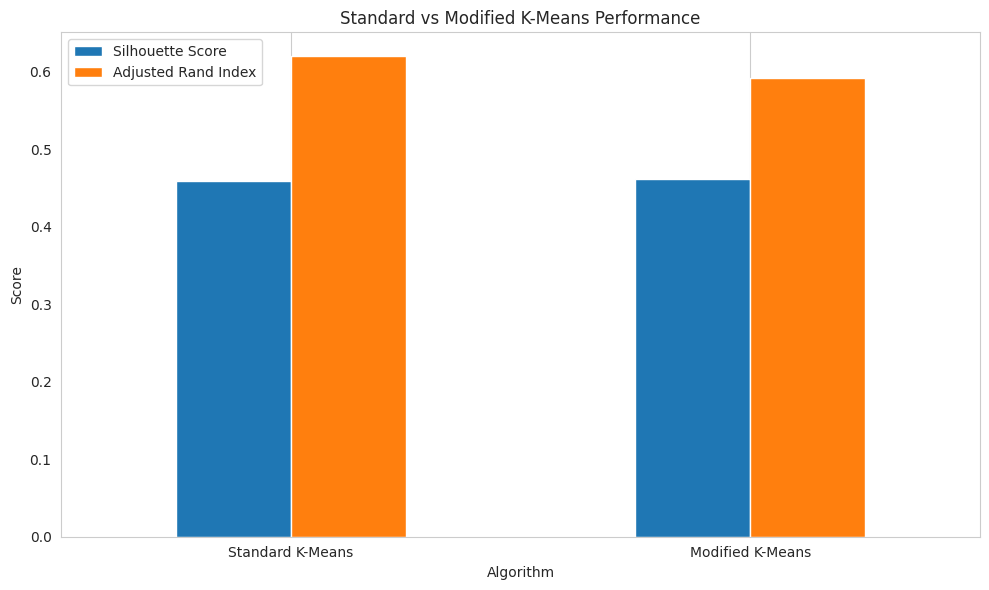

In [29]:
# Compare Silhouette Score and ARI

metrics_to_plot = [
    "Silhouette Score",
    "Adjusted Rand Index"
]

comparison_results.set_index(
    "Algorithm"
)[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Standard vs Modified K-Means Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.legend()
plt.tight_layout()
plt.show()

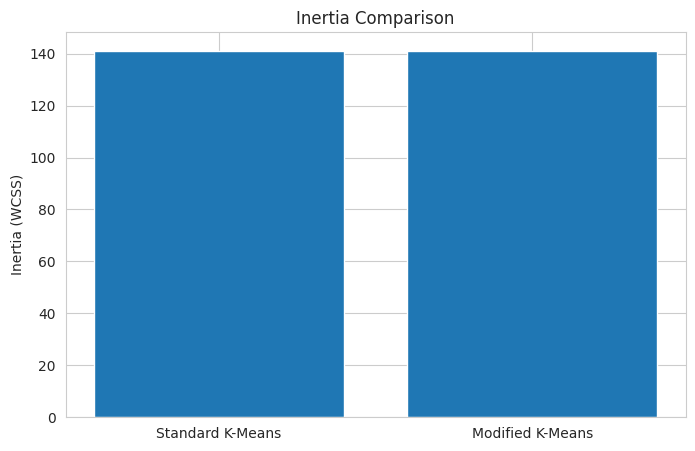

In [30]:
# Compare Inertia

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Algorithm"],
    comparison_results["Inertia (WCSS)"]
)

plt.title("Inertia Comparison")
plt.ylabel("Inertia (WCSS)")
plt.xticks(rotation=0)

plt.show()

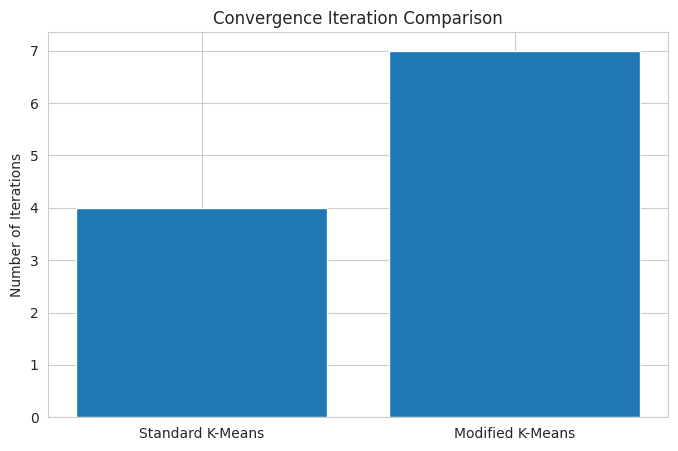

In [31]:
# Compare convergence iterations

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Algorithm"],
    comparison_results["Iterations"]
)

plt.title("Convergence Iteration Comparison")
plt.ylabel("Number of Iterations")
plt.xticks(rotation=0)

plt.show()


## Comparative Visualization

The clustering results of Standard K-Means and Modified K-Means are visualized side by side using the same feature pair.

This comparison helps identify differences in cluster assignments and centroid positions.


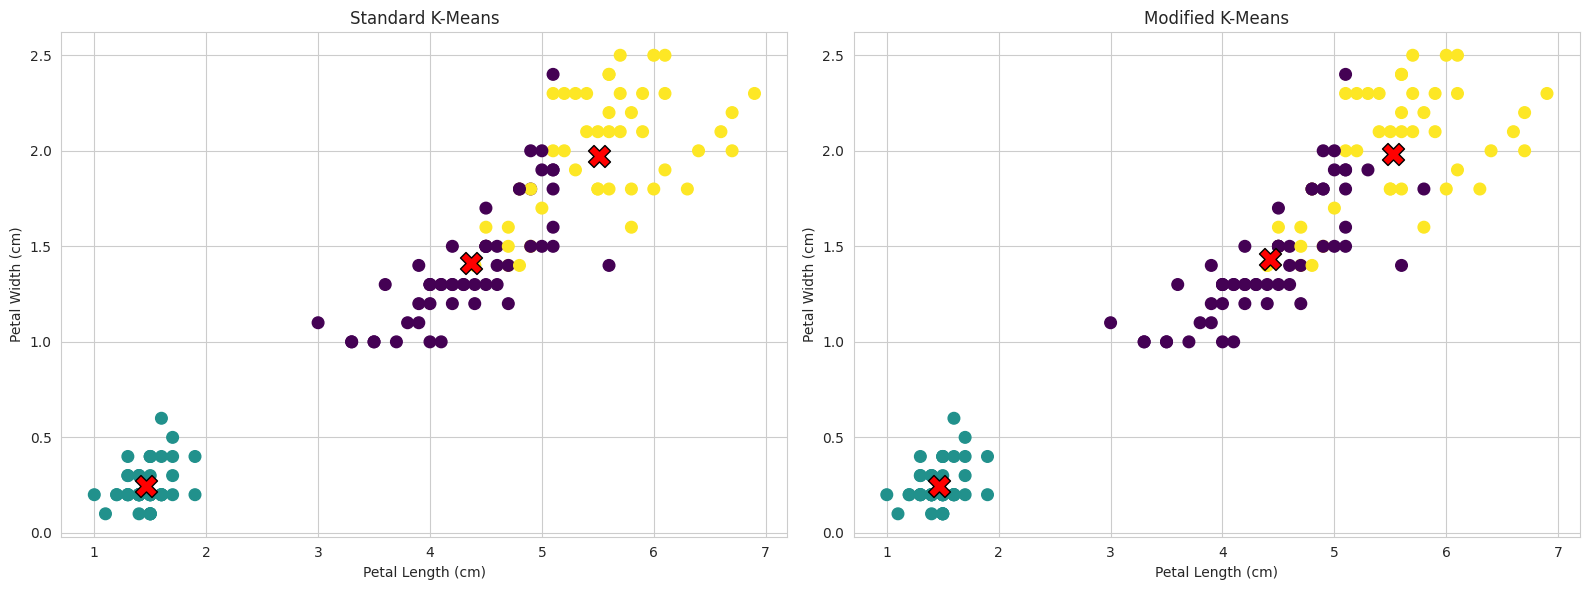

In [32]:
# Side-by-side comparison

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# Standard K-Means
axes[0].scatter(
    X["PetalLengthCm"],
    X["PetalWidthCm"],
    c=standard_labels,
    cmap="viridis",
    s=70
)

axes[0].scatter(
    scaler.inverse_transform(
        standard_centroids
    )[:, 2],
    scaler.inverse_transform(
        standard_centroids
    )[:, 3],
    marker="X",
    color="red",
    s=250,
    edgecolor="black"
)

axes[0].set_title("Standard K-Means")
axes[0].set_xlabel("Petal Length (cm)")
axes[0].set_ylabel("Petal Width (cm)")


# Modified K-Means
axes[1].scatter(
    X["PetalLengthCm"],
    X["PetalWidthCm"],
    c=modified_labels,
    cmap="viridis",
    s=70
)

axes[1].scatter(
    modified_centroids_original[:, 2],
    modified_centroids_original[:, 3],
    marker="X",
    color="red",
    s=250,
    edgecolor="black"
)

axes[1].set_title("Modified K-Means")
axes[1].set_xlabel("Petal Length (cm)")
axes[1].set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()


##  Results and Discussion

### Standard K-Means

Standard K-Means was implemented using the K-Means++ centroid initialization method.

The algorithm was evaluated using Inertia, Silhouette Score, and Adjusted Rand Index.

### Modified K-Means

The modified algorithm used a farthest-point initialization strategy.

The first centroid was selected using the dataset mean, and subsequent centroids were selected based on their minimum distances from existing centroids.

### Performance Comparison

The results of both algorithms were compared using the same dataset and feature scaling method.

The comparison focused on:

- Cluster compactness using Inertia.
- Cluster separation using Silhouette Score.
- Agreement with actual species using Adjusted Rand Index.
- Convergence behavior using iteration count.

The results indicate how centroid initialization can influence clustering performance.



## Observations

1. Both algorithms generated three clusters from the Iris dataset.
2. The dataset was standardized before clustering.
3. Modified K-Means used farthest-point initialization instead of K-Means++ initialization.
4. The initial centroid selection influenced the final clustering result.
5. The generated clusters were evaluated using Silhouette Score and Adjusted Rand Index.
6. Inertia was used to measure cluster compactness.
7. Cluster labels were compared with actual Iris species for evaluation.
8. The performance of the two algorithms was compared using numerical metrics and visualizations.
9. Modified K-Means does not necessarily outperform Standard K-Means in every metric or dataset.



##  Conclusion

In this experiment, a modified version of the K-Means clustering algorithm was implemented using a farthest-point centroid initialization strategy.

The Iris dataset was standardized and clustered into three groups using both Standard K-Means and Modified K-Means.

The clustering results were visualized using scatter plots and PCA. The algorithms were evaluated using Inertia, Silhouette Score, and Adjusted Rand Index.

The comparative analysis demonstrated that centroid initialization can influence the resulting clusters, convergence behavior, and clustering performance.

This experiment provided practical understanding of K-Means initialization strategies and the importance of evaluating clustering algorithms using multiple metrics.



##  Export Results

The final dataset is saved with the cluster labels generated by both algorithms.

The exported file can be used for further analysis and comparison.


In [33]:
# Add both cluster results to final dataset

final_results = df.copy()

final_results["Standard_KMeans_Cluster"] = standard_labels

final_results["Modified_KMeans_Cluster"] = modified_labels

display(final_results.head())

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Modified_Cluster,Standard_KMeans_Cluster,Modified_KMeans_Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1,1,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1,1,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1,1,1
3,4.6,3.1,1.5,0.2,Iris-setosa,1,1,1
4,5.0,3.6,1.4,0.2,Iris-setosa,1,1,1


In [34]:
# Save CSV

final_results.to_csv(
    "Modified_KMeans_Iris_Results.csv",
    index=False
)

print("CSV file saved successfully!")

CSV file saved successfully!


In [35]:
# Download result file from Colab

from google.colab import files

files.download("Modified_KMeans_Iris_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>